In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.model_selection import train_test_split 
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.model_selection import GridSearchCV,StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
df=pd.read_csv("MachineLearningDataSets/16-diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
df["Outcome"].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [5]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [6]:
X=df.drop("Outcome",axis=1)
y=df["Outcome"]

In [7]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)

In [8]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"] 
X_train[cols]=X_train[cols].replace(0,np.nan)                                     
X_test[cols]=X_test[cols].replace(0,np.nan) 

X_train_median=X_train[cols].median()

X_train[cols]=X_train[cols].fillna(X_train_median)                           
X_test[cols]=X_test[cols].fillna(X_train_median)                           

In [9]:
# EDA

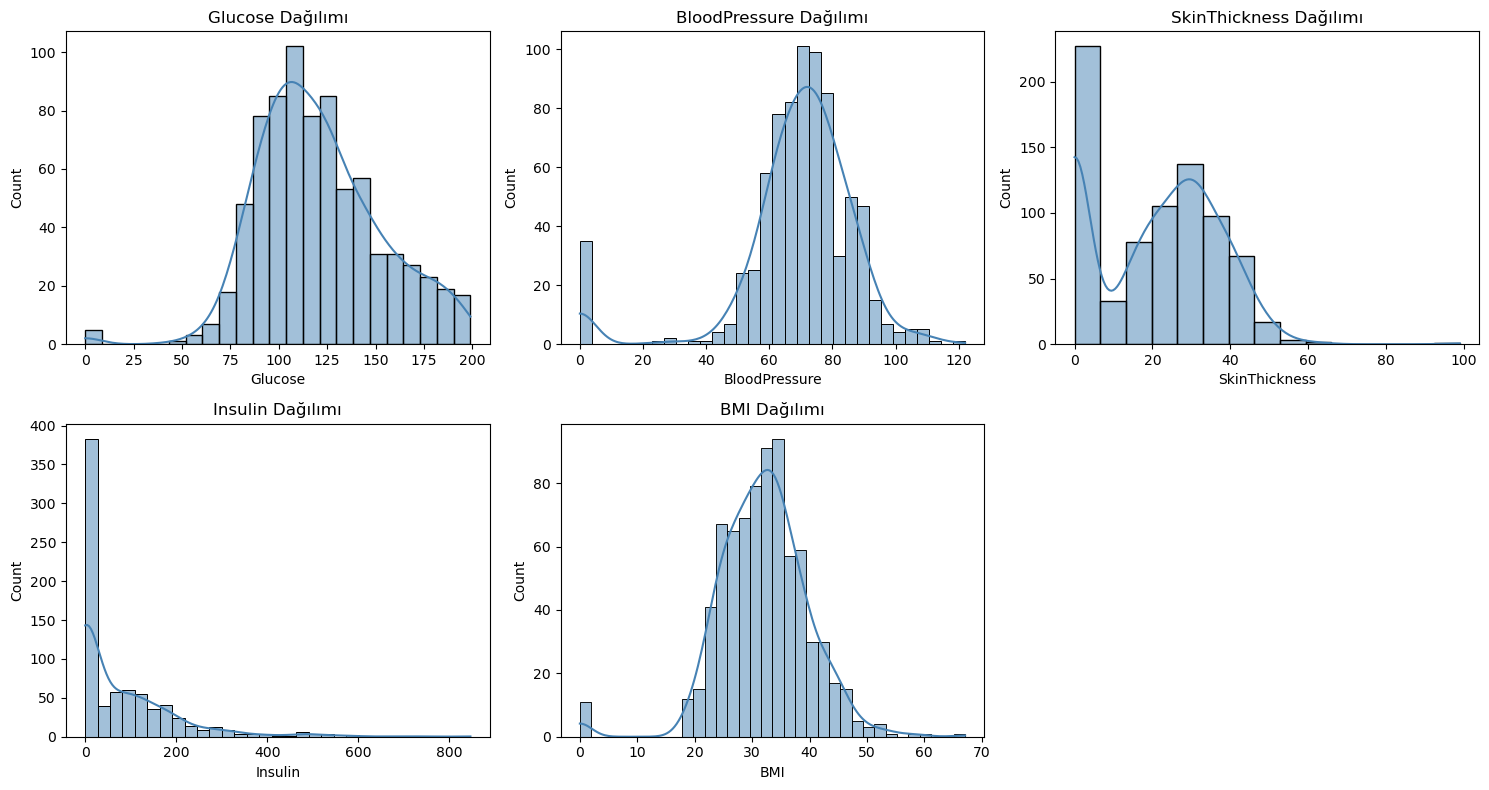

In [10]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(f"{col} Dağılımı")

# boş kalan 6. subplot'u gizle
axes[-1].axis("off")

plt.tight_layout()
plt.show()

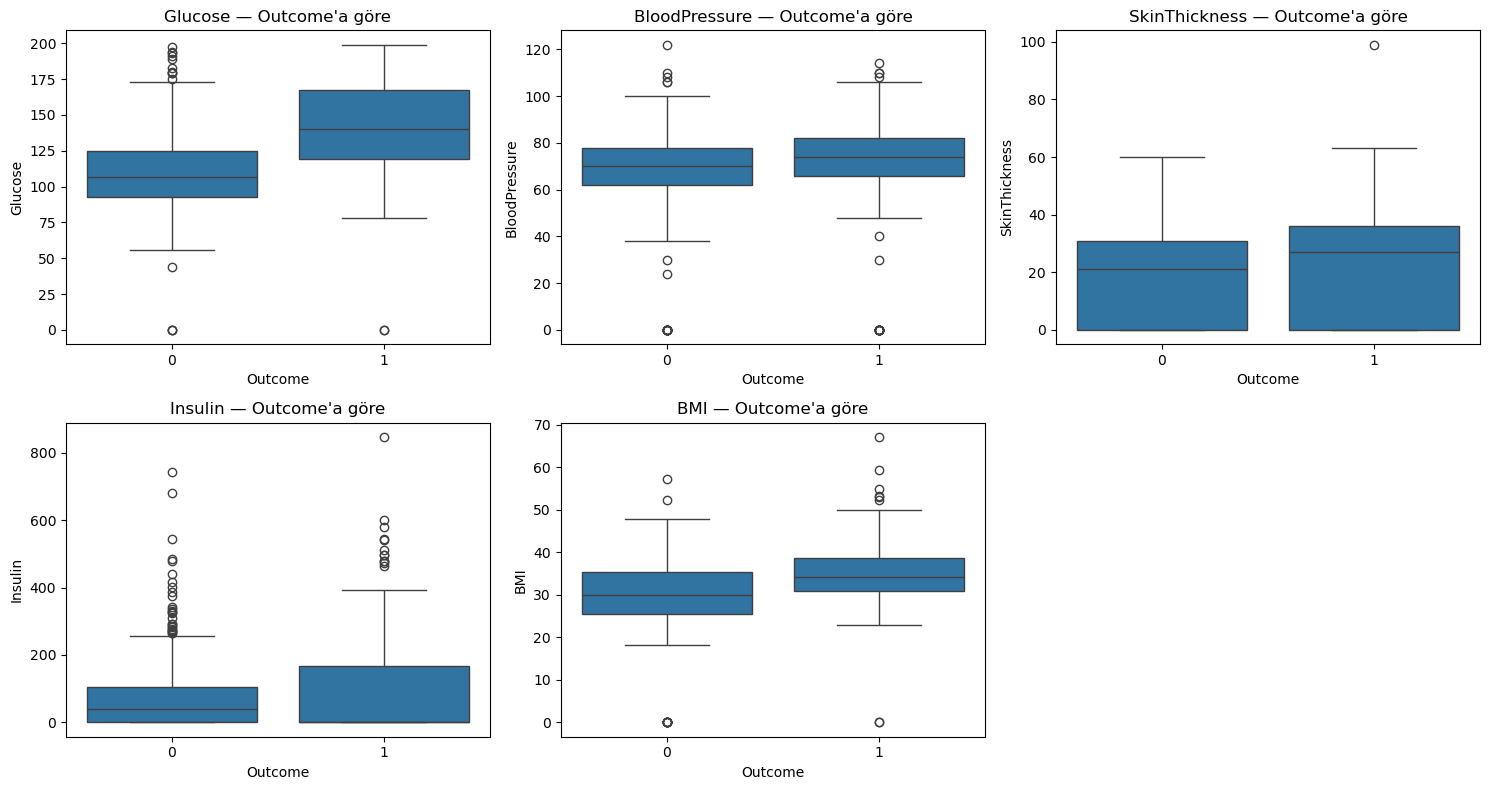

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.boxplot(data=df, x="Outcome", y=col, ax=axes[i])
    axes[i].set_title(f"{col} — Outcome'a göre")

axes[-1].axis("off")

plt.tight_layout()
plt.show()

In [11]:
adaboost=AdaBoostClassifier(random_state=42)

In [12]:
adaboost.fit(X_train,y_train)

,estimator,None
,n_estimators,50
,learning_rate,1.0
,algorithm,'deprecated'
,random_state,42


In [13]:
y_pred=adaboost.predict(X_test)

In [14]:
print(f"Accuracy:{accuracy_score(y_test,y_pred)}")
print(f"Confusion:\n{confusion_matrix(y_test,y_pred)}")
print(f"Classification:\n{classification_report(y_test,y_pred)}")

Accuracy:0.75
Confusion:
[[100  23]
 [ 25  44]]
Classification:
              precision    recall  f1-score   support

           0       0.80      0.81      0.81       123
           1       0.66      0.64      0.65        69

    accuracy                           0.75       192
   macro avg       0.73      0.73      0.73       192
weighted avg       0.75      0.75      0.75       192



In [15]:
# grid

In [16]:
params_grid = {
    "n_estimators": [50, 100, 200, 500],
    "learning_rate": [0.01, 0.1, 0.5, 1.0]
}

In [17]:
grid=GridSearchCV(estimator=AdaBoostClassifier(random_state=0),param_grid=params_grid,n_jobs=-1,verbose=3,scoring="recall")

In [18]:
grid.fit(X_train,y_train)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


,estimator,AdaBoostClass...andom_state=0)
,param_grid,"{'learning_rate': [0.01, 0.1, ...], 'n_estimators': [50, 100, ...]}"
,scoring,'recall'
,n_jobs,-1
,refit,True
,cv,None
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,estimator,None


In [19]:
grid.best_params_

{'learning_rate': 1.0, 'n_estimators': 50}

In [20]:
y_pred=grid.predict(X_test)

In [21]:
print(f"Accuracy:{accuracy_score(y_test,y_pred)}")
print(f"Confusion:\n{confusion_matrix(y_test,y_pred)}")
print(f"Classification:\n{classification_report(y_test,y_pred)}")

Accuracy:0.75
Confusion:
[[100  23]
 [ 25  44]]
Classification:
              precision    recall  f1-score   support

           0       0.80      0.81      0.81       123
           1       0.66      0.64      0.65        69

    accuracy                           0.75       192
   macro avg       0.73      0.73      0.73       192
weighted avg       0.75      0.75      0.75       192



In [22]:
# let's try with other classification algorithsm

In [23]:
df=pd.read_csv("MachineLearningDataSets/16-diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [24]:
X=df.drop("Outcome",axis=1)
y=df["Outcome"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"] 
X_train[cols]=X_train[cols].replace(0,np.nan)                                     
X_test[cols]=X_test[cols].replace(0,np.nan) 

X_train_median=X_train[cols].median()

X_train[cols]=X_train[cols].fillna(X_train_median)                           
X_test[cols]=X_test[cols].fillna(X_train_median)                           

In [25]:
models = {
    "Adaboost": AdaBoostClassifier(n_estimators=50, learning_rate=1.0, random_state=42),
    "Logistic": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "SVC":      SVC(C=1.0, kernel="rbf", class_weight="balanced", random_state=42),
    "KNN":      KNeighborsClassifier(n_neighbors=5),
    "Random":   RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42)
}

params_grids = {
    "Adaboost": {
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.1, 0.5, 1.0]
    },
    "Logistic": {
        "C": [0.01, 0.1, 1, 10],          # düzenlileştirme gücü (küçük = daha çok ceza)
        "penalty": ["l2"],
        "max_iter": [1000]                 # yakınsama için artır
    },
    "SVC": {
        "C": [0.1, 1, 10],                 # hata toleransı
        "kernel": ["rbf", "linear"],
        "gamma": ["scale", "auto"]         # rbf için karar sınırı eğriliği
    },
    "KNN": {
        "n_neighbors": [3, 5, 7, 9, 11],   # kaç komşuya bakılacak
        "weights": ["uniform", "distance"],
        "metric": ["euclidean", "manhattan"]
    },
    "Random": {
        "n_estimators": [100, 200, 300],
        "max_depth": [None, 5, 10, 20],    # ağaç derinliği (None = sınırsız)
        "min_samples_split": [2, 5, 10]
    }
}

In [26]:
def calculate_score(y_test,y_true):
    accuracy=accuracy_score(y_test,y_pred)
    matrix=confusion_matrix(y_test,y_pred)
    classification=classification_report(y_test,y_pred)    
    return accuracy,matrix,classification

In [27]:
models.items()

dict_items([('Adaboost', AdaBoostClassifier(random_state=42)), ('Logistic', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)), ('SVC', SVC(class_weight='balanced', random_state=42)), ('KNN', KNeighborsClassifier()), ('Random', RandomForestClassifier(class_weight='balanced', random_state=42))])

In [28]:
needs_scaling = {"Logistic", "SVC", "KNN"}
for name,model in models.items():
    if name in needs_scaling:
        clf=Pipeline([("Scaler",StandardScaler()),("model",model)])
    else:
        clf=model
    clf.fit(X_train,y_train)
    y_pred=clf.predict(X_test)
    accuracy,matrix,classification=calculate_score(y_test,y_pred)
    print(f"Model {name}:\n Accuracy:{accuracy}\nMatrix:\n{matrix}\nClassification:\n{classification}")
    print("-------------")

Model Adaboost:
 Accuracy:0.75
Matrix:
[[100  23]
 [ 25  44]]
Classification:
              precision    recall  f1-score   support

           0       0.80      0.81      0.81       123
           1       0.66      0.64      0.65        69

    accuracy                           0.75       192
   macro avg       0.73      0.73      0.73       192
weighted avg       0.75      0.75      0.75       192

-------------
Model Logistic:
 Accuracy:0.6927083333333334
Matrix:
[[86 37]
 [22 47]]
Classification:
              precision    recall  f1-score   support

           0       0.80      0.70      0.74       123
           1       0.56      0.68      0.61        69

    accuracy                           0.69       192
   macro avg       0.68      0.69      0.68       192
weighted avg       0.71      0.69      0.70       192

-------------
Model SVC:
 Accuracy:0.6979166666666666
Matrix:
[[81 42]
 [16 53]]
Classification:
              precision    recall  f1-score   support

           0  